# Designing reproducible Monte Carlo experiments

The first expression averages a quantity over simulated outcomes, and the second estimates the uncertainty of that average:

$$
\widehat\psi_M=\frac{1}{M}\sum_{m=1}^{M}g(Y^{(m)}),\qquad
\widehat{\operatorname{SE}}(\widehat\psi_M)=\frac{s_g}{\sqrt M}.
$$

Here, $M$ is the number of simulations; $m$ labels a simulation; $Y^{(m)}$ is its outcome; $g$ is the measured quantity. $\widehat\psi_M$ is the simulation average; $s_g$ is the sample standard deviation of $g(Y^{(m)})$; $\widehat{\operatorname{SE}}$ is estimated standard error.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image

ROOT = Path.cwd().parents[1]

from RiskLabAI.data.synthetic_data import align_params_length, heston_merton_log_returns

FIGURES = ROOT / "outputs" / "figures" / "02_synthetic_financial_environments"
TABLES = ROOT / "outputs" / "tables" / "02_synthetic_financial_environments"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {
    "background": "#FFFFFF",
    "axes": "#FFFFFF",
    "text": "#1B365D",
    "cyan": "#0072B2",
    "amber": "#C76D00",
    "green": "#00866A",
    "rose": "#B83B3B",
    "violet": "#A03A78",
    "grid": "#D9DEE5",
}
plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": 11.5,
    "figure.facecolor": palette["background"],
    "axes.facecolor": palette["axes"],
    "axes.edgecolor": palette["text"],
    "axes.labelcolor": palette["text"],
    "axes.titlecolor": palette["text"],
    "xtick.color": palette["text"],
    "ytick.color": palette["text"],
    "text.color": palette["text"],
    "grid.color": palette["grid"],
    "grid.linestyle": ":",
    "legend.facecolor": palette["axes"],
    "legend.edgecolor": palette["grid"],
    "savefig.facecolor": palette["background"],
})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def simulate_markov_path(transition, n_steps, seed, initial_state=0):
    generator = np.random.default_rng(seed)
    states = np.empty(n_steps, dtype=int)
    states[0] = initial_state
    for index in range(1, n_steps):
        states[index] = generator.choice(transition.shape[0], p=transition[states[index - 1]])
    return states
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Markov Regimes

The equations define state-change probabilities and a long-run distribution that is unchanged by one transition:

$$
p_{ij}=\mathbb P(S_{t+1}=j\mid S_t=i),\qquad
P\mathbf 1=\mathbf 1,\qquad
\pi^{\mathsf T}P=\pi^{\mathsf T},\qquad
\pi^{\mathsf T}\mathbf 1=1.
$$

Here, $S_t$ is the state at time $t$; $p_{ij}$ is the chance of moving from state $i$ to state $j.$ $P$ is the transition matrix; $\mathbf 1$ is a vector of ones; $\pi$ is the stationary probability vector; $\mathsf T$ denotes transpose.

In [2]:
transition_matrix = np.array([[0.97, 0.03], [0.12, 0.88]])
regime_names = np.array(["Calm", "Crisis"])
regimes = {
    "Calm": {"mu": 0.06, "kappa": 3.0, "theta": 0.025, "xi": 0.25, "rho": -0.60, "lam": 0.02, "m": -0.01, "v": 0.03},
    "Crisis": {"mu": -0.08, "kappa": 1.5, "theta": 0.120, "xi": 0.50, "rho": -0.75, "lam": 0.35, "m": -0.08, "v": 0.10},
}
aligned_calm, calm_length = align_params_length(regimes["Calm"])
aligned_crisis, crisis_length = align_params_length(regimes["Crisis"])
stationary_system = np.vstack((transition_matrix.T - np.eye(2), np.ones(2)))
stationary_target = np.array([0.0, 0.0, 1.0])
stationary_distribution = np.linalg.lstsq(stationary_system, stationary_target, rcond=None)[0]

regime_specification = pd.DataFrame({
    "Parameter": ["Annual drift", "Mean reversion", "Long-run variance", "Volatility of variance", "Return-variance correlation", "Jump intensity", "Mean jump size", "Jump size standard deviation"],
    "Calm": [regimes["Calm"][key] for key in ["mu", "kappa", "theta", "xi", "rho", "lam", "m", "v"]],
    "Crisis": [regimes["Crisis"][key] for key in ["mu", "kappa", "theta", "xi", "rho", "lam", "m", "v"]],
})
save_table(regime_specification, "regime_specification", "Parameters for the two Heston-Merton regimes.", "tab:regime-specification", fit=False)
display(regime_specification)

transition_stationary_summary = pd.DataFrame({
    "Regime": regime_names,
    "Probability of remaining": np.diag(transition_matrix),
    "Stationary probability": stationary_distribution,
    "Mean spell length": 1.0 / (1.0 - np.diag(transition_matrix)),
})
save_table(transition_stationary_summary, "transition_stationary_summary", "Persistence and stationary probabilities for the two-state Markov chain.", "tab:transition-stationary-summary", fit=False)
display(transition_stationary_summary.round(6))

,Parameter,Calm,Crisis
0,Annual drift,0.060,-0.08
1,Mean reversion,3,1.50
2,Long-run variance,0.025,0.12
3,Volatility of variance,0.250,0.50
4,Return-variance correlation,-0.600,-0.75
5,Jump intensity,0.020,0.35
6,Mean jump size,-0.010,-0.08
7,Jump size standard deviation,0.030,0.10


,Regime,Probability of remaining,Stationary probability,Mean spell length
0,Calm,0.97,0.8,33.333333
1,Crisis,0.88,0.2,8.333333


## Heston-Merton Path

Variance moves toward a long-run level and receives a random shock whose size grows with current variance:

$$
V_{t+1}=V_t+\kappa_t(\theta_t-V_t^+)\Delta+\xi_t\sqrt{V_t^+}\sqrt{\Delta}\,Z_{V,t},
$$

Here, $V_t$ is variance; $V_t^+=\max(V_t,0)$ keeps the square root defined; $\kappa_t$ is the rate of return toward the long-run level. $\theta_t$ is that long-run variance; $\xi_t$ is volatility of variance; $\Delta$ is the time step; $Z_{V,t}$ is a standard-normal variance shock.

The return combines drift, a variance correction, ordinary price variation, and a possible jump:

$$
R_{t+1}=\left[\mu_t-\frac12V_t^+-\lambda_t\left(m_t+\frac{v_t^2}{2}\right)\right]\Delta
+\sqrt{V_t^+}\sqrt{\Delta}\,Z_{S,t}+N_tY_t.
$$

Here, $R_{t+1}$ is the next log return; $\mu_t$ is drift; $V_t^+$ is nonnegative variance; $\Delta$ is the time step. $\lambda_t$ is jump arrival intensity; $m_t$ and $v_t$ are jump mean and standard deviation; $Z_{S,t}$ is a standard-normal price shock. $N_t$ is the number of jumps in the interval; $Y_t$ is jump size; $N_tY_t$ is the total jump contribution.

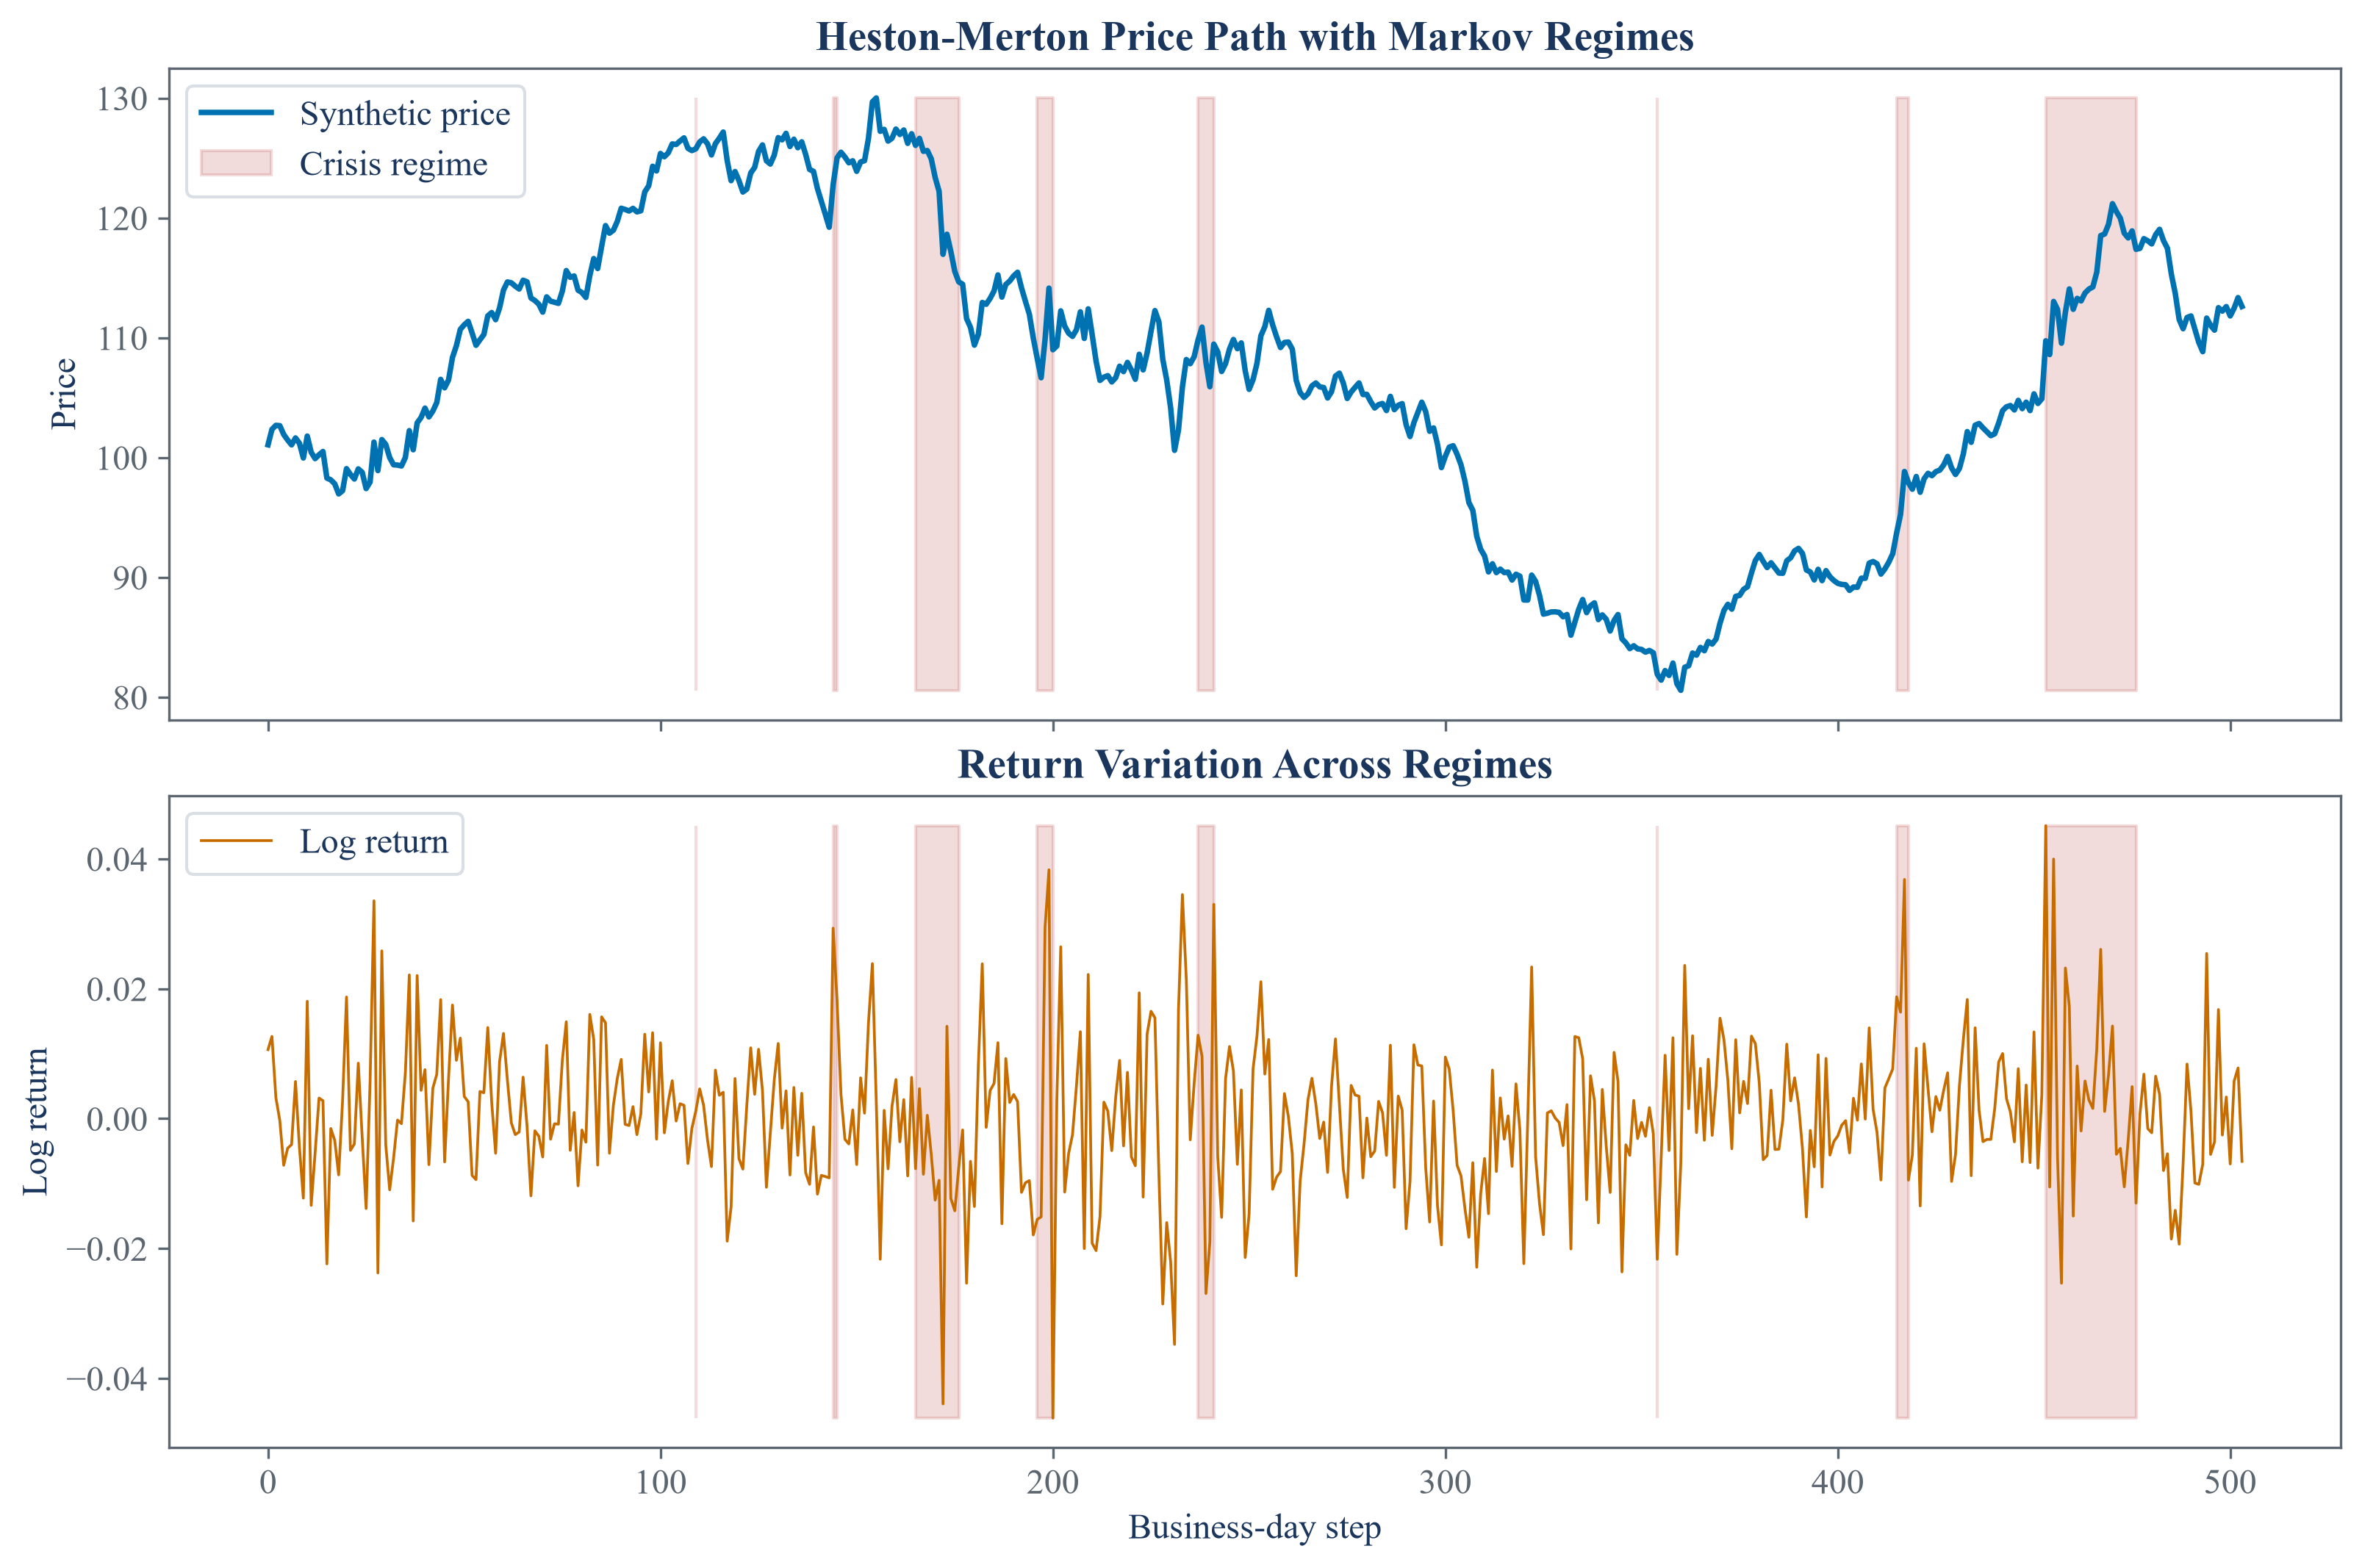

In [3]:
total_time = 2.0
n_steps = 504
regime_states = simulate_markov_path(transition_matrix, n_steps, seed=20260930)
regime_path = regime_names[regime_states]
parameter_keys = ["mu", "kappa", "theta", "xi", "rho", "lam", "m", "v"]
parameter_vectors = {
    key: np.array([regimes[name][key] for name in regime_path], dtype=float)
    for key in parameter_keys
}
regime_change = np.pad(regime_states[1:] != regime_states[:-1], (1, 0), constant_values=False)
log_returns = heston_merton_log_returns(
    total_time=total_time,
    n_steps=n_steps,
    mu_vector=parameter_vectors["mu"],
    kappa_vector=parameter_vectors["kappa"],
    theta_vector=parameter_vectors["theta"],
    xi_vector=parameter_vectors["xi"],
    rho_vector=parameter_vectors["rho"],
    lambda_vector=parameter_vectors["lam"],
    m_vector=parameter_vectors["m"],
    v_vector=parameter_vectors["v"],
    regime_change=regime_change,
    random_state=20260931,
)
prices = 100.0 * np.exp(np.cumsum(log_returns))
step_index = np.arange(n_steps)

figure, axes = plt.subplots(2, 1, figsize=(10.6, 7.0), sharex=True, constrained_layout=True)
axes[0].plot(step_index, prices, color=palette["cyan"], linewidth=1.8, label="Synthetic price")
axes[0].fill_between(step_index, prices.min(), prices.max(), where=regime_states == 1, color=palette["rose"], alpha=0.18, label="Crisis regime")
axes[0].set_ylabel("Price")
axes[0].set_title("Heston-Merton Price Path with Markov Regimes")
axes[0].legend()
axes[1].plot(step_index, log_returns, color=palette["amber"], linewidth=0.9, label="Log return")
axes[1].fill_between(step_index, log_returns.min(), log_returns.max(), where=regime_states == 1, color=palette["rose"], alpha=0.18)
axes[1].set_xlabel("Business-day step")
axes[1].set_ylabel("Log return")
axes[1].set_title("Return Variation Across Regimes")
axes[1].legend()
figure.savefig(FIGURES / "regime_price_path.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "regime_price_path.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "regime_price_path.png")))
plt.close(figure)

## Monte Carlo Uncertainty

The first expression is an approximate 95 percent interval, and the second gives its large-sample normal justification:

$$
\widehat\psi_M\pm z_{0.975}\frac{s_g}{\sqrt M},\qquad
\sqrt M\,(\widehat\psi_M-\psi)\Rightarrow\mathcal N(0,\sigma_g^2).
$$

Here, $\widehat\psi_M$ is the average from $M$ simulations; $\psi$ is the target mean; $s_g$ is the sample standard deviation. $z_{0.975}$ is the 97.5th percentile of a standard normal distribution; $\sigma_g^2$ is the variance of the measured quantity; $\Rightarrow$ denotes convergence in distribution.

In [4]:
path_count = 400
monte_carlo_steps = 252
master_sequence = np.random.SeedSequence(20260932)
child_sequences = master_sequence.spawn(path_count)
seed_pairs = np.array([child.generate_state(2, dtype=np.uint32) for child in child_sequences], dtype=np.uint32)
terminal_log_returns = np.empty(path_count)
terminal_prices = np.empty(path_count)
crisis_fractions = np.empty(path_count)

for path_index, seed_pair in enumerate(seed_pairs):
    states = simulate_markov_path(transition_matrix, monte_carlo_steps, seed=int(seed_pair[0]))
    names = regime_names[states]
    vectors = {
        key: np.array([regimes[name][key] for name in names], dtype=float)
        for key in parameter_keys
    }
    changes = np.pad(states[1:] != states[:-1], (1, 0), constant_values=False)
    path_returns = heston_merton_log_returns(
        total_time=1.0,
        n_steps=monte_carlo_steps,
        mu_vector=vectors["mu"],
        kappa_vector=vectors["kappa"],
        theta_vector=vectors["theta"],
        xi_vector=vectors["xi"],
        rho_vector=vectors["rho"],
        lambda_vector=vectors["lam"],
        m_vector=vectors["m"],
        v_vector=vectors["v"],
        regime_change=changes,
        random_state=int(seed_pair[1]),
    )
    terminal_log_returns[path_index] = path_returns.sum()
    terminal_prices[path_index] = 100.0 * np.exp(terminal_log_returns[path_index])
    crisis_fractions[path_index] = np.mean(states == 1)

def summary_row(name, values):
    estimate = float(np.mean(values))
    standard_error = float(np.std(values, ddof=1) / np.sqrt(values.size))
    return {
        "Quantity": name,
        "Estimate": estimate,
        "Monte Carlo standard error": standard_error,
        "Lower 95 percent limit": estimate - 1.96 * standard_error,
        "Upper 95 percent limit": estimate + 1.96 * standard_error,
    }

loss_indicators = terminal_prices < 100.0
monte_carlo_summary = pd.DataFrame([
    summary_row("Terminal log return", terminal_log_returns),
    summary_row("Terminal price", terminal_prices),
    summary_row("Loss probability", loss_indicators.astype(float)),
    summary_row("Crisis time fraction", crisis_fractions),
])
save_table(monte_carlo_summary, "monte_carlo_summary", "Monte Carlo estimates, standard errors, and normal-approximation intervals from 400 paths.", "tab:monte-carlo-summary")
display(monte_carlo_summary.round(6))

,Quantity,Estimate,Monte Carlo standard error,Lower 95 percent limit,Upper 95 percent limit
0,Terminal log return,0.029798,0.010932,0.008370,0.051225
1,Terminal price,105.455464,1.129363,103.241912,107.669015
2,Loss probability,0.410000,0.024622,0.361740,0.458260
3,Crisis time fraction,0.196071,0.004294,0.187654,0.204488


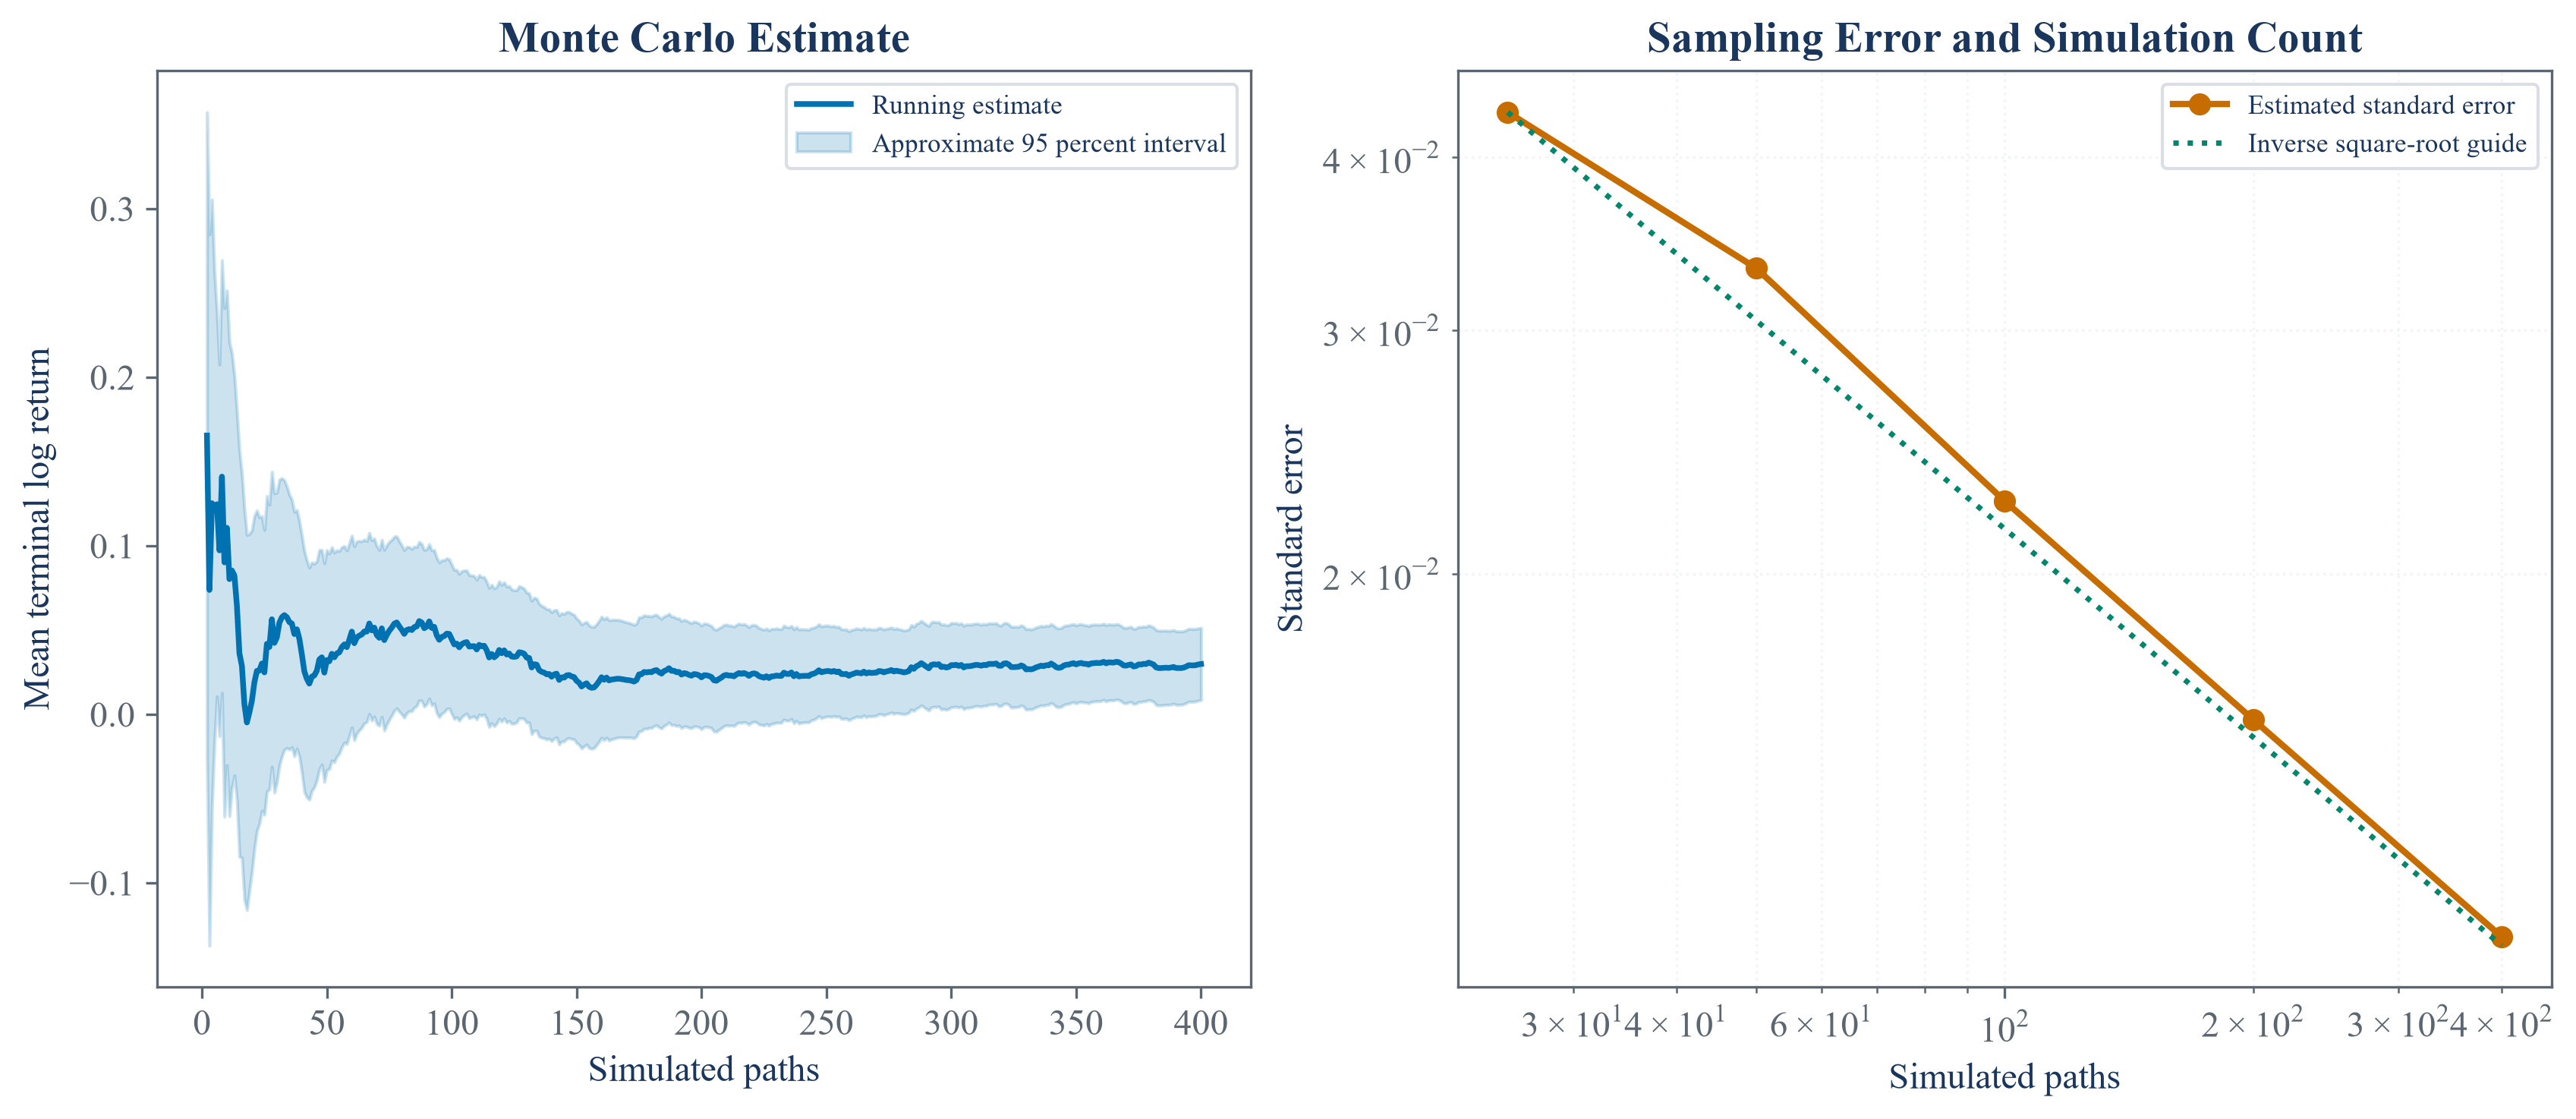

In [5]:
running_count = np.arange(2, path_count + 1)
running_mean = np.array([terminal_log_returns[:count].mean() for count in running_count])
running_standard_error = np.array([terminal_log_returns[:count].std(ddof=1) / np.sqrt(count) for count in running_count])
evaluation_counts = np.array([25, 50, 100, 200, 400])
evaluated_standard_errors = np.array([terminal_log_returns[:count].std(ddof=1) / np.sqrt(count) for count in evaluation_counts])
inverse_square_root_guide = evaluated_standard_errors[0] * np.sqrt(evaluation_counts[0] / evaluation_counts)

figure, axes = plt.subplots(1, 2, figsize=(11.2, 4.8), constrained_layout=True)
axes[0].plot(running_count, running_mean, color=palette["cyan"], linewidth=1.8, label="Running estimate")
axes[0].fill_between(running_count, running_mean - 1.96 * running_standard_error, running_mean + 1.96 * running_standard_error, color=palette["cyan"], alpha=0.20, label="Approximate 95 percent interval")
axes[0].set_xlabel("Simulated paths")
axes[0].set_ylabel("Mean terminal log return")
axes[0].set_title("Monte Carlo Estimate")
axes[0].legend(fontsize=8.5)
axes[1].loglog(evaluation_counts, evaluated_standard_errors, marker="o", color=palette["amber"], linewidth=2.0, label="Estimated standard error")
axes[1].loglog(evaluation_counts, inverse_square_root_guide, color=palette["green"], linewidth=1.7, linestyle=":", label="Inverse square-root guide")
axes[1].set_xlabel("Simulated paths")
axes[1].set_ylabel("Standard error")
axes[1].set_title("Sampling Error and Simulation Count")
axes[1].grid(True, which="both", alpha=0.32)
axes[1].legend(fontsize=8.5)
figure.savefig(FIGURES / "monte_carlo_uncertainty.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "monte_carlo_uncertainty.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "monte_carlo_uncertainty.png")))
plt.close(figure)

## Tests

In [6]:
repeated_states = simulate_markov_path(transition_matrix, n_steps, seed=20260930)
repeated_returns = heston_merton_log_returns(
    total_time=total_time,
    n_steps=n_steps,
    mu_vector=parameter_vectors["mu"],
    kappa_vector=parameter_vectors["kappa"],
    theta_vector=parameter_vectors["theta"],
    xi_vector=parameter_vectors["xi"],
    rho_vector=parameter_vectors["rho"],
    lambda_vector=parameter_vectors["lam"],
    m_vector=parameter_vectors["m"],
    v_vector=parameter_vectors["v"],
    regime_change=regime_change,
    random_state=20260931,
)
assert calm_length == crisis_length == 1
assert aligned_calm["mu"] == [regimes["Calm"]["mu"]]
assert aligned_crisis["v"] == [regimes["Crisis"]["v"]]
assert np.allclose(transition_matrix.sum(axis=1), 1.0)
assert np.all(transition_matrix >= 0.0)
assert np.allclose(stationary_distribution @ transition_matrix, stationary_distribution)
assert np.isclose(stationary_distribution.sum(), 1.0)
assert np.array_equal(regime_states, repeated_states)
assert np.array_equal(log_returns, repeated_returns)
assert prices.shape == log_returns.shape == regime_states.shape == (n_steps,)
assert np.all(np.isfinite(prices)) and np.all(prices > 0.0)
assert len(np.unique(seed_pairs[:, 0])) == path_count
assert len(np.unique(seed_pairs[:, 1])) == path_count
assert np.all(np.isfinite(terminal_prices)) and np.all(terminal_prices > 0.0)
assert monte_carlo_summary["Monte Carlo standard error"].gt(0.0).all()
assert np.all(monte_carlo_summary["Lower 95 percent limit"] < monte_carlo_summary["Estimate"])
assert np.all(monte_carlo_summary["Estimate"] < monte_carlo_summary["Upper 95 percent limit"])
assert abs(crisis_fractions.mean() - stationary_distribution[1]) < 0.08
assert evaluated_standard_errors[-1] < evaluated_standard_errors[0]